# DSpark 训练实时监控

训练在后台由 `pb_train.py` 跑（不占用这个 notebook 的 kernel），指标逐行写进 `train_log.jsonl`；这个 notebook 只读日志并重画，kernel 断了训练不受影响。

怎么看训练是在变好还是变差：
- **val tau**（上排中间，橙线）：验证集上每轮接受的 token 数，含 bonus，越高越好。第 0 步是随机初始化的起点，之后应该持续上升
- **train 与 val 的差距**：train 继续变好、val 变平或下降，就是过拟合
- **per-slot alpha**（下排中间）：蓝线应该整体高于灰色虚线（起点），并且后面的 slot 衰减得更慢
- **confidence head**（下排右）：两条线越接近，置信度头校准得越好

图里的文字用英文，因为 matplotlib 没有中文字体。

In [2]:
%matplotlib inline
import sys, importlib
sys.path.insert(0, '/home/dev/KAP/train')
import dspark_plot
importlib.reload(dspark_plot)
from dspark_plot import read, verdict, live

### 当前快照（只画一次）

step 30900/30910  epoch 10.00/10  318 ms/step  ETA 0.0 h
val tau  起点 1.005 -> 现在 1.777 (+0.771，变好)；较上一次验证 -0.000（基本持平）；最佳 1.777
训练结束；Target 权重文件 sha256 前后一致: True


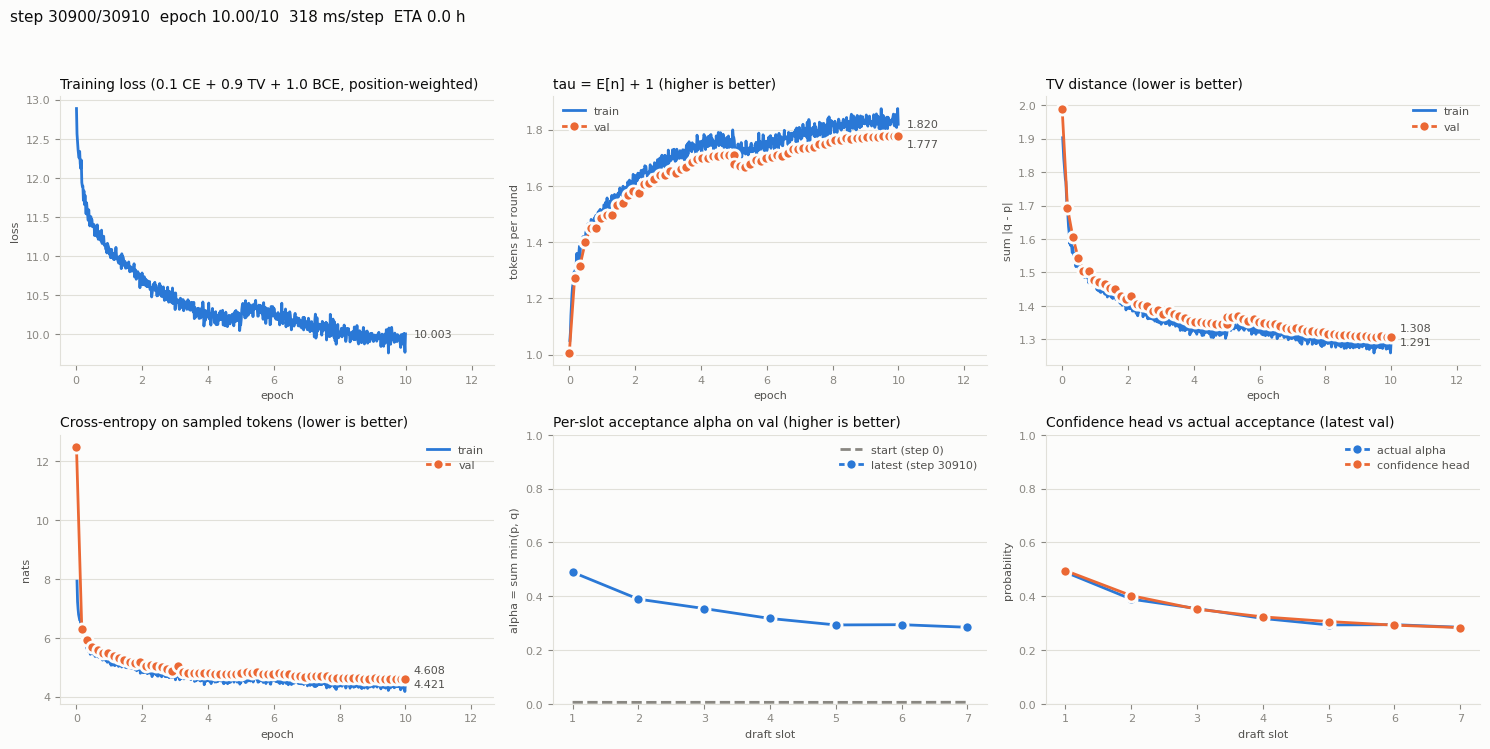

In [3]:
live(once=True)

### 实时刷新（每 30 秒重画一次，训练结束后自动停；想停可以中断这个 cell，不影响训练）

step 23150/15455  epoch 7.49/5  318 ms/step  ETA -0.7 h
val tau  起点 1.005 -> 现在 1.740 (+0.734，变好)；较上一次验证 +0.006（基本持平）；最佳 1.740
训练结束；Target 权重文件 sha256 前后一致: True


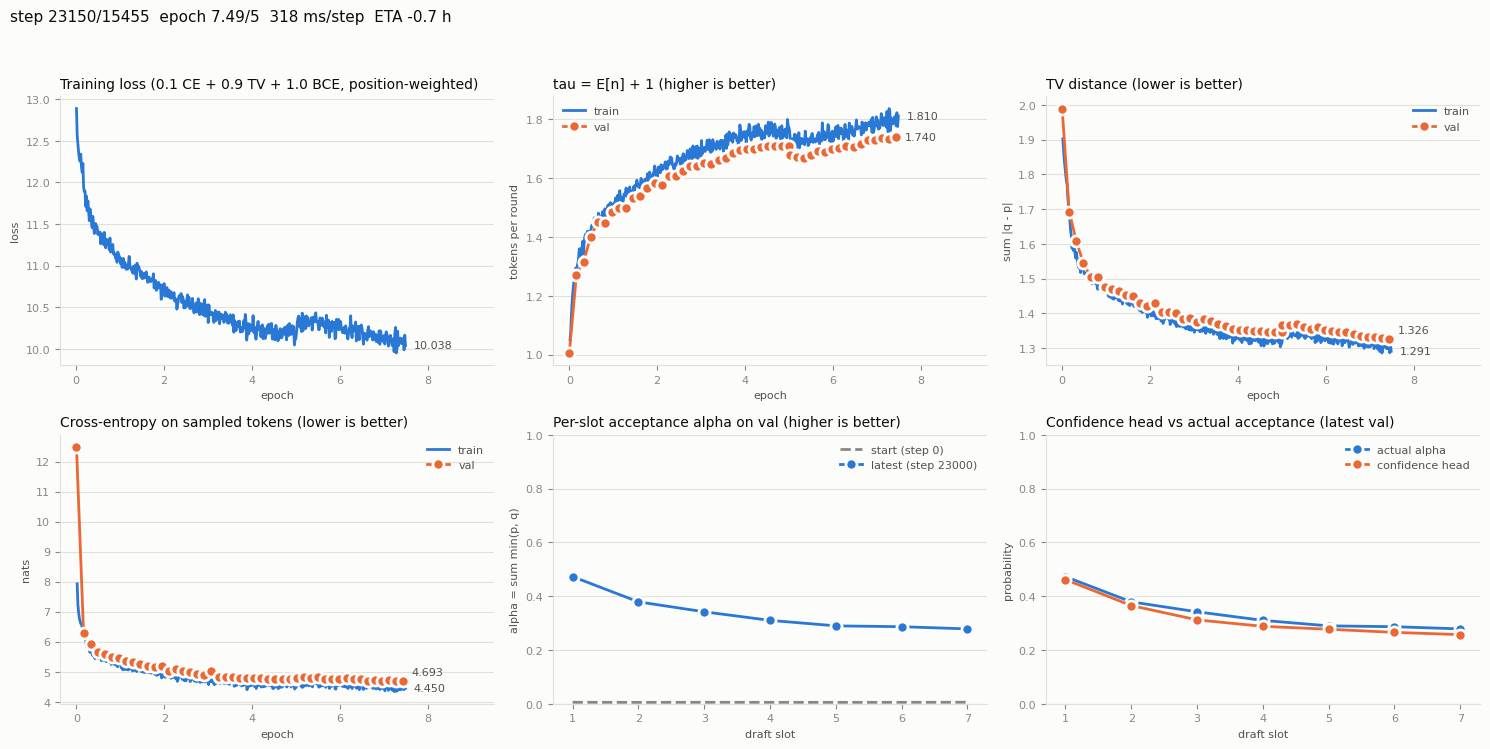

In [14]:
live(interval=30)

### 训练结束后的汇总（起点 vs 最后一次验证）

In [8]:
recs = read()
va = [r for r in recs if r['t'] == 'val']
for r in ([va[0], va[-1]] if va else []):
    print(f"step {r['step']:6d}  tau {r['tau']:.3f}  tau_argmax {r['tau_argmax']:.3f}  CE {r['ce']:.3f}  TV {r['tv']:.3f}")
    print('   alpha/slot', ' '.join(f'{x:.2f}' for x in r['alpha']))
done = [r for r in recs if r['t'] == 'done']
print(done[-1] if done else 'training not finished')

step      0  tau 1.005  tau_argmax 1.001  CE 12.482  TV 1.990
   alpha/slot 0.01 0.01 0.01 0.01 0.01 0.01 0.01
step   5000  tau 1.540  tau_argmax 1.563  CE 5.177  TV 1.451
   alpha/slot 0.38 0.31 0.27 0.25 0.24 0.23 0.23
training not finished
